# ⚽💰 Football Finance Intelligence
## Module 4 — Un modèle de machine learning pour estimer la valeur d'un joueur

**Idée :** entraîner un modèle qui apprend à estimer la valeur marchande d'un joueur à partir de ses caractéristiques (âge, poste, championnat, contrat, statistiques…).

**Applications :**
- **Repérer les joueurs sous-évalués** : valeur réelle < valeur estimée par le modèle → cibles de recrutement
- **Comprendre ce qui fait la valeur** d'un joueur, grâce à SHAP (explicabilité du modèle)

### Étapes
1. Construction du jeu de données
2. Séparation apprentissage / test
3. Modèle de référence : régression linéaire
4. Modèles avancés : Random Forest et XGBoost
5. Évaluation de la précision
6. Explication des décisions avec SHAP
7. Détection des joueurs sous-évalués

In [1]:
!pip install duckdb -q
!curl -sLO https://pub-e682421888d945d684bcae8890b0ec20.r2.dev/data/transfermarkt-datasets.duckdb

import duckdb
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

con = duckdb.connect("transfermarkt-datasets.duckdb", read_only=True)
def q(sql):
    return con.sql(sql).df()

# Toutes les colonnes de players, avec leur type
print(q("DESCRIBE players")[["column_name", "column_type"]].to_string(index=False))

# Un exemple de joueur
display(q("SELECT * FROM players WHERE name LIKE '%Hakimi%' LIMIT 1").T)

                         column_name column_type
                           player_id     INTEGER
                          first_name     VARCHAR
                           last_name     VARCHAR
                                name     VARCHAR
                         last_season     VARCHAR
                     current_club_id     VARCHAR
                         player_code     VARCHAR
                    country_of_birth     VARCHAR
                       city_of_birth     VARCHAR
              country_of_citizenship     VARCHAR
                       date_of_birth   TIMESTAMP
                        sub_position     VARCHAR
                            position     VARCHAR
                                foot     VARCHAR
                        height_in_cm     INTEGER
            contract_expiration_date   TIMESTAMP
                          agent_name     VARCHAR
                           image_url     VARCHAR
                  international_caps     INTEGER
                 int

,0
player_id,398073
first_name,Achraf
last_name,Hakimi
name,Achraf Hakimi
last_season,2025
current_club_id,583
player_code,achraf-hakimi
country_of_birth,Spain
city_of_birth,Madrid
country_of_citizenship,Morocco


## 1. Construction du jeu de données
### Variables utilisées
| Variable | Source | Pourquoi |
|---|---|---|
| Âge | `date_of_birth` | Facteur n°1 de la valeur (Module 2) |
| Poste et sous-poste | `position`, `sub_position` | La valeur varie selon le poste |
| Pied fort, taille | `foot`, `height_in_cm` | Caractéristiques physiques |
| Années de contrat restantes | `contract_expiration_date` | Un joueur en fin de contrat peut partir libre, donc vaut moins |
| Sélections et buts internationaux | `international_caps`, `international_goals` | Niveau et réputation |
| Championnat | `current_club_domestic_competition_id` | Effet ligue (Module 1) |
| Valeur du reste de l'effectif | calculée | Niveau du club |
| Minutes, buts, passes décisives (2 dernières saisons) | `appearances` | Performance récente |

**Cible :** `market_value_in_eur`, la valeur marchande actuelle.

⚠️ **Variable exclue :** `highest_market_value_in_eur` (valeur maximale historique). Pour un joueur à son pic, elle est égale à la valeur actuelle : l'utiliser reviendrait à donner la réponse au modèle. C'est une **fuite de données** (*data leakage*).

In [2]:
df = q("""
WITH stats AS (
    SELECT a.player_id,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2025 THEN a.minutes_played ELSE 0 END) AS minutes_n,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2025 THEN a.goals          ELSE 0 END) AS buts_n,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2025 THEN a.assists        ELSE 0 END) AS passes_n,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2025 THEN 1                ELSE 0 END) AS matchs_n,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2024 THEN a.minutes_played ELSE 0 END) AS minutes_n1,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2024 THEN a.goals          ELSE 0 END) AS buts_n1,
           SUM(CASE WHEN TRY_CAST(g.season AS INT) = 2024 THEN a.assists        ELSE 0 END) AS passes_n1
    FROM appearances a
    JOIN games g ON a.game_id = g.game_id
    WHERE TRY_CAST(g.season AS INT) IN (2024, 2025)
    GROUP BY 1
),
joueurs AS (
    SELECT p.*,
           SUM(p.market_value_in_eur) OVER (PARTITION BY p.current_club_id)
             - p.market_value_in_eur AS valeur_club_autres
    FROM players p
    WHERE TRY_CAST(p.last_season AS INT) >= 2025
      AND p.market_value_in_eur > 0
)
SELECT
    j.player_id, j.name, j.current_club_name AS club,
    j.current_club_domestic_competition_id AS ligue,
    j.country_of_citizenship AS nationalite,
    j.position, j.sub_position, j.foot, j.height_in_cm AS taille,
    DATE_DIFF('day', CAST(j.date_of_birth AS DATE), DATE '2026-07-01') / 365.25 AS age,
    DATE_DIFF('day', DATE '2026-07-01', CAST(j.contract_expiration_date AS DATE)) / 365.25 AS annees_contrat,
    COALESCE(j.international_caps, 0)  AS selections,
    COALESCE(j.international_goals, 0) AS buts_internationaux,
    j.valeur_club_autres / 1e6         AS valeur_club_M,
    COALESCE(s.minutes_n, 0)  AS minutes_n,
    COALESCE(s.buts_n, 0)     AS buts_n,
    COALESCE(s.passes_n, 0)   AS passes_n,
    COALESCE(s.matchs_n, 0)   AS matchs_n,
    COALESCE(s.minutes_n1, 0) AS minutes_n1,
    COALESCE(s.buts_n1, 0)    AS buts_n1,
    COALESCE(s.passes_n1, 0)  AS passes_n1,
    j.market_value_in_eur / 1e6 AS valeur_M
FROM joueurs j
LEFT JOIN stats s ON j.player_id = s.player_id
""")

print(f"Nombre de joueurs : {len(df):,}")
print("\nValeurs manquantes par colonne :")
manquants = df.isna().sum()
print(manquants[manquants > 0].to_string())

print("\nStatistiques de la valeur (M€) :")
print(df["valeur_M"].describe().round(2).to_string())

# Distribution de la valeur : brute vs logarithme
from plotly.subplots import make_subplots
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=("Valeur brute (M€)", "Logarithme de la valeur"))
fig.add_trace(go.Histogram(x=df["valeur_M"], nbinsx=80, name="Valeur"), row=1, col=1)
fig.add_trace(go.Histogram(x=np.log(df["valeur_M"]), nbinsx=80, name="log(Valeur)"), row=1, col=2)
fig.update_layout(title="Distribution des valeurs marchandes", showlegend=False)
fig.show()

# La fiche de Hakimi dans notre jeu de données
display(df[df["name"] == "Achraf Hakimi"].T)

Nombre de joueurs : 18,404

Valeurs manquantes par colonne :
club              2194
ligue             2194
sub_position        29
foot              1404
taille             705
annees_contrat    3434

Statistiques de la valeur (M€) :
count    18404.00
mean         2.96
std          8.52
min          0.01
25%          0.25
50%          0.60
75%          2.00
max        200.00


,1329
player_id,398073
name,Achraf Hakimi
club,Paris Saint-Germain
ligue,FR1
nationalite,Morocco
position,Defender
sub_position,Right-Back
foot,right
taille,180
age,27.655031


### Lecture
**Une distribution très asymétrique :** 18 404 joueurs, valeur médiane **0,6 M€**, moyenne **3,0 M€**, maximum **200 M€**. 75 % des joueurs valent moins de 2 M€.

**On modélisera le logarithme de la valeur**, qui suit une distribution en cloche :
- sans transformation, le modèle se concentrerait sur les quelques stars et négligerait la majorité des joueurs ;
- le logarithme mesure les erreurs **en pourcentage** : une erreur de 1 M€ est grave pour un joueur à 2 M€, négligeable pour un joueur à 80 M€.

Les pics réguliers de l'histogramme correspondent aux **paliers d'estimation** de Transfermarkt.

### Traitement des valeurs manquantes
| Colonne | Manquants | Traitement |
|---|---|---|
| Club, championnat | 2 194 | Joueurs **retirés** (statistiques incomplètes, valeur du club non calculable) |
| Années de contrat | 3 434 | Médiane + indicateur « contrat inconnu » |
| Pied fort | 1 404 | Catégorie « inconnu » |
| Taille | 705 | Médiane |
| Sous-poste | 29 | Poste principal |

## 2. Préparation et séparation des données
- **Nettoyage :** traitement des valeurs manquantes (voir tableau ci-dessus).
- **Nouvelles variables :** âge au carré (la relation âge-valeur est en cloche, Module 2), minutes sur 2 saisons, buts + passes décisives par 90 minutes (calculé si au moins 450 minutes jouées).
- **Encodage :** les catégories (championnat, poste, pied) sont transformées en colonnes de 0 et 1 (*one-hot encoding*).
- **Séparation :** 80 % des joueurs pour l'**apprentissage**, 20 % pour le **test**. Le modèle est évalué sur des joueurs qu'il n'a jamais vus.

### Mesures de précision
- **R²** (sur le logarithme) : part des écarts de valeur expliquée par le modèle
- **Erreur moyenne absolue (M€)**
- **Erreur médiane (%)** : erreur relative du joueur typique

## 3. Modèle de référence : la régression linéaire
Le modèle le plus simple, qui sert de point de comparaison pour les modèles plus avancés.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# --- 1. Nettoyage ---
data = df[df["ligue"].notna()].copy()
data["sub_position"] = data["sub_position"].fillna(data["position"])
data["foot"] = data["foot"].fillna("inconnu")
data["taille"] = data["taille"].fillna(data["taille"].median())
data["contrat_inconnu"] = data["annees_contrat"].isna().astype(int)
data["annees_contrat"] = data["annees_contrat"].fillna(data["annees_contrat"].median()).clip(lower=0)

# --- 2. Nouvelles variables ---
data["age_carre"] = data["age"] ** 2
data["minutes_2s"] = data["minutes_n"] + data["minutes_n1"]
contributions = data["buts_n"] + data["passes_n"] + data["buts_n1"] + data["passes_n1"]
data["ga_par90"] = np.where(data["minutes_2s"] >= 450,
                            contributions / data["minutes_2s"] * 90, 0)
data["log_valeur_club"] = np.log1p(data["valeur_club_M"].clip(lower=0))
data["log_valeur"] = np.log(data["valeur_M"])

num_cols = ["age", "age_carre", "annees_contrat", "contrat_inconnu", "taille",
            "selections", "buts_internationaux", "log_valeur_club",
            "minutes_n", "buts_n", "passes_n", "matchs_n",
            "minutes_n1", "buts_n1", "passes_n1", "minutes_2s", "ga_par90"]
cat_cols = ["ligue", "position", "sub_position", "foot"]

# --- 3. Encodage des catégories ---
X = pd.get_dummies(data[num_cols + cat_cols], columns=cat_cols,
                   drop_first=True, dtype=float)
y = data["log_valeur"]
print(f"Jeu de données : {X.shape[0]:,} joueurs × {X.shape[1]} variables")

# --- 4. Séparation apprentissage / test ---
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Apprentissage : {len(X_train):,} joueurs | Test : {len(X_test):,} joueurs")

# --- 5. Fonction d'évaluation (réutilisée pour tous les modèles) ---
resultats = []
def evaluer(nom, y_vrai_log, y_pred_log):
    vrai, pred = np.exp(y_vrai_log), np.exp(y_pred_log)
    res = {"Modèle": nom,
           "R² (log)": round(r2_score(y_vrai_log, y_pred_log), 3),
           "Erreur moyenne (M€)": round(mean_absolute_error(vrai, pred), 2),
           "Erreur médiane (%)": round(np.median(np.abs(pred - vrai) / vrai) * 100, 1)}
    resultats.append(res)
    return res

# --- 6. Régression linéaire ---
lin = LinearRegression()
lin.fit(X_train, y_train)
pred_lin = lin.predict(X_test)
print(evaluer("Régression linéaire", y_test, pred_lin))

# --- 7. Graphique : valeur prédite vs valeur réelle ---
fig = px.scatter(x=np.exp(y_test), y=np.exp(pred_lin), log_x=True, log_y=True, opacity=0.4,
                 title="Régression linéaire : valeur prédite vs valeur réelle (joueurs du test)",
                 labels={"x": "Valeur réelle (M€)", "y": "Valeur prédite (M€)"})
fig.add_trace(go.Scatter(x=[0.01, 200], y=[0.01, 200], mode="lines",
                         line=dict(dash="dash", color="black"), name="Prédiction parfaite"))
fig.show()

Jeu de données : 16,210 joueurs × 68 variables
Apprentissage : 12,968 joueurs | Test : 3,242 joueurs
{'Modèle': 'Régression linéaire', 'R² (log)': 0.697, 'Erreur moyenne (M€)': 1.68, 'Erreur médiane (%)': np.float64(49.0)}


### Lecture
| Indicateur | Régression linéaire |
|---|---|
| R² (log) | 0,697 |
| Erreur moyenne | 1,68 M€ |
| Erreur médiane | 49 % |

- Le modèle explique **70 %** des écarts de valeur, mais l'**erreur médiane de 49 %** reste trop élevée pour une utilisation en recrutement.
- **Régression vers la moyenne :** le modèle surestime les joueurs de faible valeur (points au-dessus de la diagonale à gauche) et sous-estime les joueurs les plus chers (points en dessous à droite).
- **Cause :** la régression linéaire additionne les effets un par un. Elle ne capture pas les **combinaisons** de caractéristiques (jeune + titulaire + Premier League + international), qui font la valeur des meilleurs joueurs.
- Les bandes verticales correspondent aux paliers d'estimation de Transfermarkt.

## 4. Modèles avancés : Random Forest et XGBoost
**Random Forest :** 300 arbres de décision, chacun entraîné sur un échantillon aléatoire de joueurs. La prédiction finale est la **moyenne** des 300 arbres (« sagesse des foules »).

**XGBoost (gradient boosting) :** les arbres sont construits **successivement**, chaque nouvel arbre corrigeant les erreurs des précédents.

Contrairement à la régression linéaire, ces modèles capturent les **interactions** entre variables (par exemple : jeune **et** titulaire **et** en Premier League).

In [4]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# --- Random Forest ---
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                           n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
evaluer("Random Forest", y_test, pred_rf)

# --- XGBoost ---
xgb = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
evaluer("XGBoost", y_test, pred_xgb)

# --- Tableau comparatif ---
comparaison = pd.DataFrame(resultats).drop_duplicates("Modèle", keep="last")
display(comparaison)

fig = px.bar(comparaison, x="Modèle", y="Erreur médiane (%)", color="Modèle",
             text="Erreur médiane (%)",
             title="Comparaison des modèles : erreur médiane (plus c'est bas, mieux c'est)")
fig.update_layout(showlegend=False)
fig.show()

# --- Graphique du meilleur modèle ---
meilleur = comparaison.sort_values("Erreur médiane (%)").iloc[0]["Modèle"]
pred_best = pred_xgb if meilleur == "XGBoost" else pred_rf
fig = px.scatter(x=np.exp(y_test), y=np.exp(pred_best), log_x=True, log_y=True, opacity=0.4,
                 title=f"{meilleur} : valeur prédite vs valeur réelle (joueurs du test)",
                 labels={"x": "Valeur réelle (M€)", "y": "Valeur prédite (M€)"})
fig.add_trace(go.Scatter(x=[0.01, 200], y=[0.01, 200], mode="lines",
                         line=dict(dash="dash", color="black"), name="Prédiction parfaite"))
fig.show()

,Modèle,R² (log),Erreur moyenne (M€),Erreur médiane (%)
0,Régression linéaire,0.697,1.68,49.0
1,Random Forest,0.741,1.36,43.0
2,XGBoost,0.781,1.23,40.5


### Lecture
| Modèle | R² (log) | Erreur moyenne | Erreur médiane |
|---|---|---|---|
| Régression linéaire | 0,697 | 1,68 M€ | 49,0 % |
| Random Forest | 0,741 | 1,36 M€ | 43,0 % |
| **XGBoost** | **0,781** | **1,23 M€** | **40,5 %** |

**XGBoost est retenu.** Par rapport à la régression linéaire, il réduit l'erreur moyenne de **27 %** et explique **78 %** des écarts de valeur. La capacité à capturer les interactions entre variables fait la différence, en particulier pour les joueurs les plus chers, désormais bien mieux estimés.

**Pourquoi une erreur médiane encore élevée (40 %) ?**
- Absence de **données de performance avancées** (xG, duels, passes progressives), non disponibles en accès libre depuis janvier 2026.
- Facteurs non mesurés : **potentiel, blessures, médiatisation**.
- **Paliers d'estimation** de Transfermarkt : la valeur cible est elle-même imprécise, surtout pour les joueurs de faible valeur.

👉 La limite principale vient des **données disponibles**, pas du modèle.

## 5. Précision par niveau de valeur
On mesure l'erreur médiane du modèle selon la valeur réelle des joueurs.

## 6. Explicabilité du modèle : SHAP
**SHAP** (SHapley Additive exPlanations), issu de la théorie des jeux, mesure pour chaque joueur la **contribution de chaque variable** à sa valeur estimée.
- **Importance globale :** contribution moyenne de chaque variable, tous joueurs confondus.
- **Graphique en essaim :** chaque point est un joueur. À droite, la variable augmente la valeur ; à gauche, elle la diminue. Couleur rouge = valeur élevée de la variable, bleue = valeur faible.

*Les contributions sont exprimées en logarithme de la valeur : +0,7 correspond environ à une valeur multipliée par 2.*

 tranche  nb_joueurs  erreur_mediane
< 0,5 M€        1432            43.4
0,5-2 M€         969            41.2
 2-10 M€         568            40.3
10-30 M€         200            30.7
 > 30 M€          73            26.8


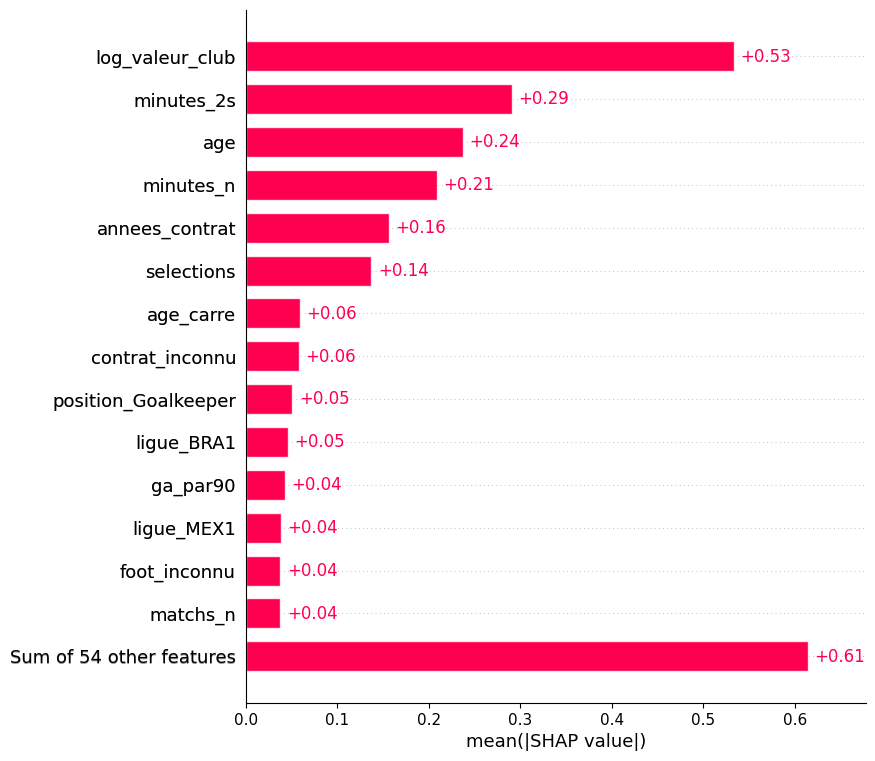

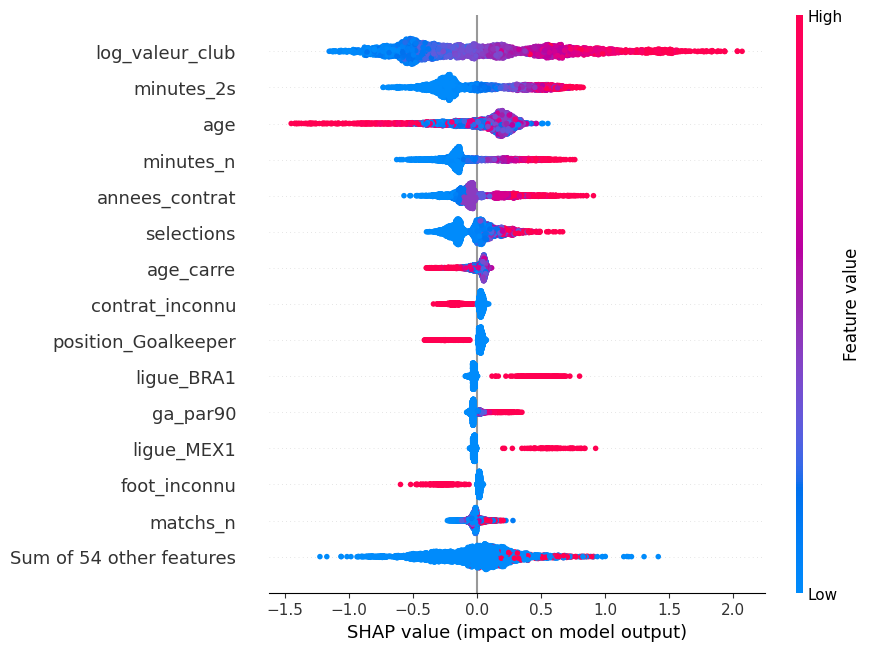

In [5]:
!pip install shap -q
import shap
import xgboost

# --- 1. Précision par niveau de valeur ---
test = pd.DataFrame({"vrai": np.exp(y_test), "pred": np.exp(pred_xgb)})
test["erreur_pct"] = (test["pred"] - test["vrai"]).abs() / test["vrai"] * 100
test["tranche"] = pd.cut(test["vrai"], bins=[0, 0.5, 2, 10, 30, 250],
                         labels=["< 0,5 M€", "0,5-2 M€", "2-10 M€", "10-30 M€", "> 30 M€"])
prec = (test.groupby("tranche", observed=True)
            .agg(nb_joueurs=("vrai", "count"), erreur_mediane=("erreur_pct", "median"))
            .reset_index())

fig = px.bar(prec, x="tranche", y="erreur_mediane",
             text=prec["erreur_mediane"].round(0).astype(int).astype(str) + "%",
             title="XGBoost : erreur médiane selon la valeur réelle du joueur",
             labels={"tranche": "Valeur réelle", "erreur_mediane": "Erreur médiane (%)"})
fig.show()
print(prec.round(1).to_string(index=False))

# --- 2. Valeurs SHAP (calculées directement par XGBoost) ---
contribs = xgb.get_booster().predict(xgboost.DMatrix(X_test), pred_contribs=True)
explication = shap.Explanation(values=contribs[:, :-1],
                               base_values=contribs[:, -1],
                               data=X_test.values,
                               feature_names=list(X_test.columns))

shap.plots.bar(explication, max_display=15)
shap.plots.beeswarm(explication, max_display=15)

### Lecture : précision par niveau de valeur
| Valeur réelle | Nb de joueurs | Erreur médiane |
|---|---|---|
| < 0,5 M€ | 1 432 | 43 % |
| 0,5-2 M€ | 969 | 41 % |
| 2-10 M€ | 568 | 40 % |
| 10-30 M€ | 200 | 31 % |
| > 30 M€ | 73 | **27 %** |

Le modèle est **nettement plus précis pour les joueurs les plus chers**, ceux qui comptent le plus dans une décision de recrutement.

### Lecture : ce qui fait la valeur d'un joueur (SHAP)
1. **Le niveau du club (de loin le 1ᵉʳ facteur).** Jouer dans un club riche peut multiplier la valeur par environ 7. Le club est à la fois un signal de qualité et un facteur de visibilité.
2. **Le temps de jeu.** Être titulaire augmente fortement la valeur. Les minutes jouées comptent bien plus que les buts et passes décisives par 90 minutes.
3. **L'âge.** Les joueurs âgés voient leur valeur divisée jusqu'à environ 4, ce qui confirme la dépréciation observée au Module 2.
4. **La durée du contrat.** Un long contrat augmente la valeur (jusqu'à environ ×2,5). Un joueur en fin de contrat peut partir libre.
5. **Les sélections nationales** augmentent la valeur.
6. **Les gardiens** valent moins, à caractéristiques égales.
7. **Les informations manquantes** (contrat, pied) sont associées à une valeur plus faible : un joueur peu documenté est souvent un joueur peu suivi.

🔍 **Énigme :** jouer au Brésil (`BRA1`) ou au Mexique (`MEX1`) augmente la valeur estimée. Hypothèse : les matchs de ces championnats sont absents de la base, leurs joueurs auraient donc 0 minute jouée, et le modèle compenserait avec la variable du championnat. Vérification ci-dessous.

## 7. Applications du modèle
### 7.1 Vérification de l'énigme Brésil / Mexique
Comparaison des minutes jouées par championnat.

### 7.2 Pourquoi Achraf Hakimi vaut-il ce qu'il vaut ?
Graphique en cascade (*waterfall*) : on part de la valeur moyenne, puis chaque caractéristique du joueur ajoute (rouge) ou retire (bleu) de la valeur jusqu'à l'estimation finale.

### 7.3 Les joueurs sous-évalués
**Méthode :** validation croisée en 5 blocs : chaque joueur est estimé par un modèle entraîné **sans lui**, pour éviter que le modèle ne « connaisse » déjà sa valeur.

**Ratio = valeur estimée ÷ valeur réelle.** Un ratio de 2 signifie que le modèle estime le joueur à deux fois sa valeur actuelle.

**Profil ciblé :** 26 ans maximum, au moins 1 500 minutes jouées en 2025/26, valeur d'au moins 2 M€.

Minutes jouées par championnat (2 dernières saisons) :


,nb_joueurs,minutes_mediane,pct_zero_minute
ligue,,,
BRA1,637,0.0,76.8
MEX1,496,0.0,87.9
GB1,692,2585.0,6.1
FR1,537,1955.0,6.9
ES1,595,2482.0,6.1


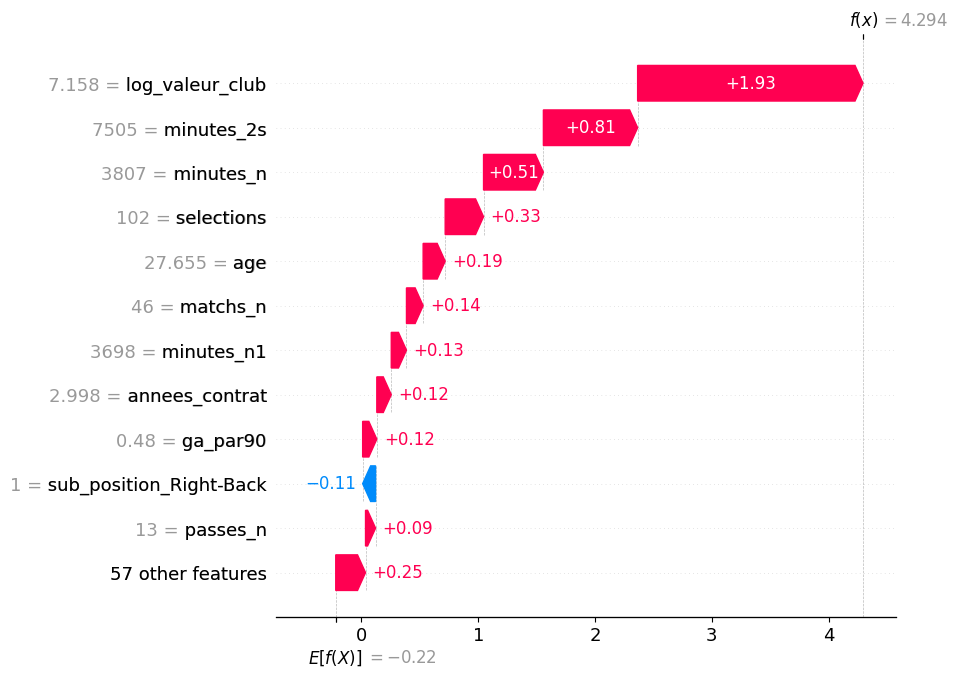

Achraf Hakimi : valeur réelle 80 M€ | valeur estimée par le modèle 73.3 M€

971 joueurs correspondent au profil ciblé

💎 Top 20 des joueurs potentiellement sous-évalués :


,name,club,ligue,nationalite,position,age,minutes_n,valeur_M,valeur_estimee_M,ratio
8139,Jayden Meghoma,Brentford FC,GB1,England,Defender,20.01,2798.0,2.0,31.480000,15.74
6557,Kaique Pereira,Sociedade Esportiva Palmeiras,BRA1,Brazil,Goalkeeper,23.21,2520.0,2.0,10.420000,5.21
6738,Christopher Wooh,Stade Rennais FC,FR1,Cameroon,Defender,24.78,2313.0,5.0,19.920000,3.98
5737,Danilo Veiga,US Lecce,IT1,Portugal,Defender,23.76,3145.0,2.5,9.730000,3.89
2831,Tochukwu Nnadi,Olympique Marseille,FR1,Nigeria,Midfield,23.00,1771.0,4.5,16.639999,3.70
401,Ivan Smolcic,Como 1907,IT1,Croatia,Defender,25.87,1900.0,3.5,12.850000,3.67
6551,Diogo Travassos,Sporting CP,PO1,Portugal,Defender,22.25,2436.0,6.0,21.420000,3.57
4926,Enric Llansana,RSC Anderlecht,BE1,Netherlands,Midfield,25.22,2254.0,2.0,6.820000,3.41
4656,Lucas Hey,RSC Anderlecht,BE1,Denmark,Defender,23.22,3084.0,2.5,8.340000,3.34
3124,Naves,Sociedade Esportiva Palmeiras,BRA1,Brazil,Defender,24.15,2915.0,4.0,12.810000,3.20



🇲🇦 Joueurs marocains (au moins 900 minutes en 2025/26), triés par ratio :


,name,club,ligue,nationalite,position,age,minutes_n,valeur_M,valeur_estimee_M,ratio
3120,Nabil Touaizi,FC Alverca,PO1,Morocco,Midfield,25.41,2849.0,0.8,3.770000,4.71
932,Walid Cheddira,SSC Napoli,IT1,Morocco,Attack,28.44,1280.0,2.0,8.350000,4.18
3582,Youssef El Arabi,FC Nantes,FR1,Morocco,Attack,39.41,938.0,0.1,0.390000,3.90
1965,Amine Harit,Olympique Marseille,FR1,Morocco,Attack,29.03,1566.0,5.0,11.330000,2.27
8609,Youssef Maleh,US Lecce,IT1,Morocco,Midfield,27.86,1566.0,1.5,3.180000,2.12
315,Amine El Ouazzani,SC Braga,PO1,Morocco,Attack,24.96,1108.0,2.5,5.240000,2.10
5620,Mohamed Nassoh,NAC Breda,NL1,Morocco,Midfield,23.43,1916.0,0.7,1.130000,1.61
3318,Youssef Enríquez,Deportivo Alavés,ES1,Morocco,Defender,20.73,1611.0,4.0,6.420000,1.60
2256,Ayoub El Kaabi,Olympiakos Syndesmos Filathlon Peiraios,GR1,Morocco,Attack,33.02,2976.0,4.5,6.770000,1.50
1372,Bilal El Khannouss,VfB Stuttgart,L1,Morocco,Midfield,22.14,3182.0,35.0,47.369999,1.35


In [6]:
from sklearn.model_selection import KFold, cross_val_predict

# --- 1. Vérification Brésil / Mexique ---
verif = (data.groupby("ligue")
             .agg(nb_joueurs=("player_id", "count"),
                  minutes_mediane=("minutes_2s", "median"),
                  pct_zero_minute=("minutes_2s", lambda s: (s == 0).mean() * 100)))
print("Minutes jouées par championnat (2 dernières saisons) :")
display(verif.loc[["BRA1", "MEX1", "GB1", "FR1", "ES1"]].round(1))

# --- 2. Le cas Hakimi ---
idx = data.index[data["name"] == "Achraf Hakimi"][0]
c = xgb.get_booster().predict(xgboost.DMatrix(X.loc[[idx]]), pred_contribs=True)
expl_h = shap.Explanation(values=c[0, :-1], base_values=c[0, -1],
                          data=X.loc[idx].values, feature_names=list(X.columns))
shap.plots.waterfall(expl_h, max_display=12)
print(f"Achraf Hakimi : valeur réelle {data.loc[idx, 'valeur_M']:.0f} M€ "
      f"| valeur estimée par le modèle {np.exp(c.sum()):.1f} M€")

# --- 3. Validation croisée : chaque joueur estimé par un modèle qui ne l'a jamais vu ---
modele_cv = XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6,
                         subsample=0.8, colsample_bytree=0.8, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
pred_oof = cross_val_predict(modele_cv, X, y, cv=kf)

data["valeur_estimee_M"] = np.exp(pred_oof)
data["ratio"] = data["valeur_estimee_M"] / data["valeur_M"]

cibles = data[(data["valeur_M"] >= 2) & (data["age"] <= 26) & (data["minutes_n"] >= 1500)].copy()
print(f"\n{len(cibles)} joueurs correspondent au profil ciblé")

cols = ["name", "club", "ligue", "nationalite", "position", "age",
        "minutes_n", "valeur_M", "valeur_estimee_M", "ratio"]
print("\n💎 Top 20 des joueurs potentiellement sous-évalués :")
display(cibles.nlargest(20, "ratio")[cols].round(2))

# Graphique : valeur réelle vs estimée pour le profil ciblé
cibles["statut"] = np.where(cibles["ratio"] >= 1.5, "Sous-évalué (ratio ≥ 1,5)",
                   np.where(cibles["ratio"] <= 0.67, "Surévalué (ratio ≤ 0,67)", "Juste prix"))
fig = px.scatter(cibles, x="valeur_M", y="valeur_estimee_M", color="statut",
                 log_x=True, log_y=True, hover_name="name",
                 hover_data={"club": True, "age": ":.0f", "ratio": ":.2f", "statut": False},
                 color_discrete_map={"Sous-évalué (ratio ≥ 1,5)": "#00CC96",
                                     "Juste prix": "#AAAAAA",
                                     "Surévalué (ratio ≤ 0,67)": "#EF553B"},
                 title="Joueurs de 26 ans ou moins, titulaires : valeur réelle vs valeur estimée",
                 labels={"valeur_M": "Valeur réelle (M€)",
                         "valeur_estimee_M": "Valeur estimée (M€)", "statut": ""})
fig.add_trace(go.Scatter(x=[2, 200], y=[2, 200], mode="lines",
                         line=dict(dash="dash", color="black"), name="Juste prix"))
fig.show()

# Bonus 🇲🇦 : les internationaux marocains
maroc = data[(data["nationalite"] == "Morocco") & (data["minutes_n"] >= 900)]
print("\n🇲🇦 Joueurs marocains (au moins 900 minutes en 2025/26), triés par ratio :")
display(maroc.sort_values("ratio", ascending=False)[cols].head(15).round(2))

### Lecture
**1. Énigme résolue :** 77 % des joueurs du championnat brésilien et 88 % du championnat mexicain ont **0 minute** dans la base (contre environ 6 % en Europe). Les matchs de ces championnats ne sont pas couverts, et le modèle compense par la variable du championnat. Effet pervers : les rares joueurs de ces championnats ayant des minutes (autres compétitions) reçoivent un double bonus. **Kaique Pereira** et **Naves** (Palmeiras) sont donc des artefacts du top 20.

**2. Achraf Hakimi 🇲🇦 : à son juste prix.** Valeur réelle 80 M€, estimation 73,3 M€ (écart de 8 %).
| Facteur | Contribution (log) | Effet approximatif |
|---|---|---|
| Joue au PSG | +1,93 | ×7 |
| 7 505 minutes sur 2 saisons | +0,81 | ×2,2 |
| 102 sélections | +0,33 | ×1,4 |
| 27,7 ans (encore dans le plateau) | +0,19 | ×1,2 |
| 0,48 but/passe décisive par 90 min | +0,12 | ×1,1 |
| Poste d'arrière droit | −0,11 | ×0,9 |

**3. Joueurs potentiellement sous-évalués :** Christopher Wooh (Rennes, ×4,0), Tochukwu Nnadi (Marseille, ×3,7), Diogo Travassos (Sporting, ×3,6), Adrián Liso (Getafe), Deniz Gül (Porto), Félix Correia (Lille). Les championnats formateurs (Belgique, Portugal, Pays-Bas) sont bien représentés, ce qui est cohérent avec le Module 3.
⚠️ Jayden Meghoma (Brentford, ratio 15,7) : valeur réelle probablement non mise à jour, à vérifier.

**4. Une prime de potentiel invisible pour le modèle :** entre 10 et 40 M€, de nombreux jeunes joueurs paraissent « surévalués ». Leur prix intègre un potentiel futur que le modèle ne mesure pas (Module 2).

**5. Joueurs marocains :** **Bilal El Khannouss** (Stuttgart, 22 ans) est estimé à 47,4 M€ pour une valeur de 35 M€. Youssef Enríquez (Alavés, 20 ans) et Amine Harit (Marseille) ressortent également.
⚠️ *Limite : les joueurs **prêtés** sont rattachés à leur club propriétaire (cas probable de Walid Cheddira), ce qui fausse la variable « niveau du club ».*

### 7.4 Correction du modèle
1. **Exclusion des championnats non couverts** (plus de 30 % de joueurs à 0 minute), puis nouvel entraînement par validation croisée.
2. **Contrôle de fraîcheur** : un joueur dont la dernière estimation Transfermarkt date de plus d'un an est signalé (valeur réelle possiblement obsolète).

In [7]:
# --- 1. Championnats avec des données de matchs ---
couverture = data.groupby("ligue")["minutes_2s"].apply(lambda s: (s == 0).mean() * 100)
exclus = couverture[couverture >= 30].index.tolist()
print("Championnats exclus (matchs non couverts) :", exclus)

data2 = data[~data["ligue"].isin(exclus)].copy()
X2 = X.loc[data2.index]
X2 = X2.loc[:, X2.nunique() > 1]          # retire les colonnes devenues inutiles
y2 = y.loc[data2.index]

# --- 2. Nouvel entraînement par validation croisée ---
pred_oof2 = cross_val_predict(modele_cv, X2, y2, cv=kf)
vrai, pred = np.exp(y2), np.exp(pred_oof2)
print(f"\nModèle corrigé sur {len(data2):,} joueurs : "
      f"R² = {r2_score(y2, pred_oof2):.3f} | "
      f"erreur médiane = {np.median(np.abs(pred - vrai) / vrai) * 100:.1f} %")

data2["valeur_estimee_M"] = pred
data2["ratio"] = data2["valeur_estimee_M"] / data2["valeur_M"]

# --- 3. Contrôle de fraîcheur des valeurs ---
fraicheur = q("SELECT player_id, MAX(date) AS derniere_estimation FROM player_valuations GROUP BY 1")
data2 = data2.merge(fraicheur, on="player_id", how="left").set_index(data2.index)
data2["valeur_ancienne"] = pd.to_datetime(data2["derniere_estimation"]) < pd.Timestamp("2025-07-01")
print(f"Joueurs dont la valeur date de plus d'un an : {data2['valeur_ancienne'].sum():,}")

# --- 4. Nouveau top 20 ---
cibles2 = data2[(data2["valeur_M"] >= 2) & (data2["age"] <= 26) & (data2["minutes_n"] >= 1500)]
cols2 = ["name", "club", "ligue", "nationalite", "position", "age", "minutes_n",
         "valeur_M", "valeur_estimee_M", "ratio", "derniere_estimation", "valeur_ancienne"]
print("\n💎 Top 20 corrigé des joueurs potentiellement sous-évalués :")
display(cibles2.nlargest(20, "ratio")[cols2].round(2))

# Hakimi et El Khannouss avec le modèle corrigé
display(data2[data2["name"].isin(["Achraf Hakimi", "Bilal El Khannouss"])][cols2].round(2))

Championnats exclus (matchs non couverts) : ['A1', 'ARG1', 'AUS1', 'BRA1', 'C1', 'COL1', 'JAP1', 'KR1', 'MEX1', 'MLS1', 'NO1', 'PL1', 'RO1', 'RSK1', 'SA1', 'SE1', 'SER1', 'TS1']

Modèle corrigé sur 7,287 joueurs : R² = 0.879 | erreur médiane = 32.7 %
Joueurs dont la valeur date de plus d'un an : 257

💎 Top 20 corrigé des joueurs potentiellement sous-évalués :


,name,club,ligue,nationalite,position,age,minutes_n,valeur_M,valeur_estimee_M,ratio,derniere_estimation,valeur_ancienne
8139,Jayden Meghoma,Brentford FC,GB1,England,Defender,20.01,2798.0,2.0,28.740000,14.37,2026-05-20,False
6551,Diogo Travassos,Sporting CP,PO1,Portugal,Defender,22.25,2436.0,6.0,22.370001,3.73,2026-05-28,False
6738,Christopher Wooh,Stade Rennais FC,FR1,Cameroon,Defender,24.78,2313.0,5.0,17.379999,3.48,2026-05-26,False
89,Tamerlan Musaev,PFK CSKA Moskva,RU1,Russia,Attack,24.92,2035.0,2.5,8.310000,3.32,2026-05-26,False
2831,Tochukwu Nnadi,Olympique Marseille,FR1,Nigeria,Midfield,23.00,1771.0,4.5,14.900000,3.31,2026-06-01,False
3386,Adrián Liso,Getafe CF,ES1,Spain,Attack,21.25,1801.0,3.0,9.740000,3.25,2026-06-05,False
4926,Enric Llansana,RSC Anderlecht,BE1,Netherlands,Midfield,25.22,2254.0,2.0,6.390000,3.20,2026-06-04,False
401,Ivan Smolcic,Como 1907,IT1,Croatia,Defender,25.87,1900.0,3.5,10.050000,2.87,2026-05-29,False
4656,Lucas Hey,RSC Anderlecht,BE1,Denmark,Defender,23.22,3084.0,2.5,6.830000,2.73,2026-06-04,False
5737,Danilo Veiga,US Lecce,IT1,Portugal,Defender,23.76,3145.0,2.5,6.760000,2.71,2026-05-29,False


,name,club,ligue,nationalite,position,age,minutes_n,valeur_M,valeur_estimee_M,ratio,derniere_estimation,valeur_ancienne
1329,Achraf Hakimi,Paris Saint-Germain,FR1,Morocco,Defender,27.66,3807.0,80.0,73.059998,0.91,2026-06-01,False
1372,Bilal El Khannouss,VfB Stuttgart,L1,Morocco,Midfield,22.14,3182.0,35.0,42.119999,1.20,2026-05-27,False


### Lecture
**1. Un modèle nettement amélioré**
| | Modèle initial | Modèle corrigé |
|---|---|---|
| Joueurs | 16 210 | 7 287 |
| R² (log) | 0,781 | **0,879** |
| Erreur médiane | 40,5 % | **32,7 %** |

L'exclusion des 18 championnats sans données de matchs (Brésil, Mexique, MLS, Arabie saoudite, Japon, Suisse, Autriche…) améliore fortement la précision. *La comparaison n'est pas parfaitement équitable (population différente, mieux documentée), mais elle confirme que **la qualité des données compte plus que la complexité du modèle**.*

**2. Hypothèse rejetée :** la valeur de Jayden Meghoma est à jour (mai 2026). Nouvelle hypothèse : un **prêt** (minutes jouées dans un autre club que le club propriétaire). Vérification ci-dessous.

**3. Le top 20 corrigé**
- **Défenseurs surreprésentés** (9 sur 20, plus 2 gardiens) : le marché valorise davantage les attaquants. À temps de jeu égal, un défenseur titulaire est moins cher.
- **Décote géopolitique :** les joueurs des clubs russes (Musaev, Saus) apparaissent sous-évalués. Depuis 2022, ces clubs sont exclus des compétitions européennes, un contexte que le modèle ne mesure pas.
- **Athletic Bilbao** (Rego, Navarro) : politique de recrutement basque et ventes rares, donc une opportunité difficile à concrétiser.

**4. Joueurs marocains 🇲🇦 :** Achraf Hakimi reste à son juste prix (ratio 0,91). Bilal El Khannouss est légèrement sous-évalué (35 M€ → 42,1 M€ estimés).

### 7.5 Vérification : l'effet des prêts
On regarde **pour quel club** Jayden Meghoma et Walid Cheddira ont réellement joué leurs matchs en 2025/26.

In [9]:
colonnes_export = ["player_id", "name", "club", "ligue", "nationalite", "position",
                   "sub_position", "age", "annees_contrat", "selections", "minutes_n",
                   "buts_n", "passes_n", "valeur_M", "valeur_estimee_M", "ratio"]
data2[colonnes_export].round(3).to_csv("valorisation_joueurs.csv", index=False)
xgb.save_model("modele_valorisation_xgb.json")

from google.colab import files
files.download("valorisation_joueurs.csv")
files.download("modele_valorisation_xgb.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
def verifier_clubs(nom):
    return q(f"""
    SELECT a.player_name, c.name AS club_des_matchs, a.competition_id,
           COUNT(*) AS matchs, SUM(a.minutes_played) AS minutes
    FROM appearances a
    JOIN games g      ON a.game_id = g.game_id
    LEFT JOIN clubs c ON a.player_club_id = c.club_id
    WHERE a.player_name = '{nom}'
      AND TRY_CAST(g.season AS INT) = 2025
    GROUP BY 1, 2, 3
    ORDER BY minutes DESC
    """)

display(verifier_clubs("Jayden Meghoma"))
display(verifier_clubs("Walid Cheddira"))

,player_name,club_des_matchs,competition_id,matchs,minutes
0,Jayden Meghoma,Rangers FC,SC1,27,2040.0
1,Jayden Meghoma,Rangers FC,EL,8,496.0
2,Jayden Meghoma,Rangers FC,CLQ,2,160.0
3,Jayden Meghoma,Rangers FC,SFA,3,102.0


,player_name,club_des_matchs,competition_id,matchs,minutes
0,Walid Cheddira,US Lecce,IT1,17,1003.0
1,Walid Cheddira,US Sassuolo,IT1,16,208.0
2,Walid Cheddira,US Sassuolo,CIT,1,69.0


### Lecture : hypothèse du prêt confirmée
- **Jayden Meghoma**, enregistré à Brentford (Premier League), a joué **toute sa saison 2025/26 aux Rangers** (championnat écossais, Ligue Europa, coupe d'Écosse).
- **Walid Cheddira**, enregistré à Naples, a joué pour **Lecce** puis **Sassuolo**.

Le modèle attribue à ces joueurs le niveau de leur **club propriétaire**, alors qu'ils évoluent dans un autre club, ce qui gonfle artificiellement leur valeur estimée. Leur valeur réelle est cohérente : c'est le modèle qui se trompait.

👉 **Amélioration possible :** remplacer le club propriétaire par le **club où le joueur a joué le plus de minutes** dans la saison, et ajouter une variable « joueur prêté ».

---
# ✅ Conclusion du Module 4 — Modèle de valorisation des joueurs

### Les 5 messages clés
1. **XGBoost est le meilleur modèle.** Il explique 78 % des écarts de valeur (contre 70 % pour la régression linéaire), grâce à sa capacité à capturer les combinaisons de caractéristiques.
2. **La qualité des données compte plus que la complexité du modèle.** En retirant les championnats sans données de matchs, le R² passe à **0,88** et l'erreur médiane de 40 % à **33 %**.
3. **Ce qui fait la valeur d'un joueur (SHAP) :** d'abord le **niveau du club**, puis le **temps de jeu**, l'**âge**, la **durée du contrat** et les **sélections**. Les buts et passes décisives comptent beaucoup moins que le fait d'être titulaire.
4. **Des opportunités de recrutement identifiées :** des défenseurs titulaires des championnats formateurs (Travassos, Wooh, Hey), avec des limites à garder en tête (décote géopolitique des clubs russes, politique spécifique de l'Athletic Bilbao).
5. **Joueurs marocains 🇲🇦 :** Achraf Hakimi est à son juste prix (ratio 0,91), Bilal El Khannouss est légèrement sous-évalué (35 M€ → 42 M€).

### Démarche de validation
- **Validation croisée** : chaque joueur est estimé par un modèle qui ne l'a jamais vu.
- **Détection et correction de biais** : championnats non couverts (Brésil, Mexique…), valeurs obsolètes, joueurs prêtés.
- **Hypothèses testées** : la valeur obsolète de Meghoma (rejetée), puis le prêt (confirmée).

### Limites et pistes d'amélioration
- Utiliser le **club réel** des joueurs prêtés plutôt que leur club propriétaire.
- Ajouter des **statistiques avancées** (xG, duels, passes progressives), aujourd'hui difficiles d'accès.
- Le modèle ne mesure ni le **potentiel**, ni les **blessures**, ni le **contexte géopolitique**.

👉 Le modèle est un **outil de présélection** : il indique où regarder, mais la décision finale relève de l'analyse humaine (vidéo, scouting, contexte).

➡️ **Module suivant :** focus Maroc 🇲🇦 et agents IA.